# Lab 3

## 1A

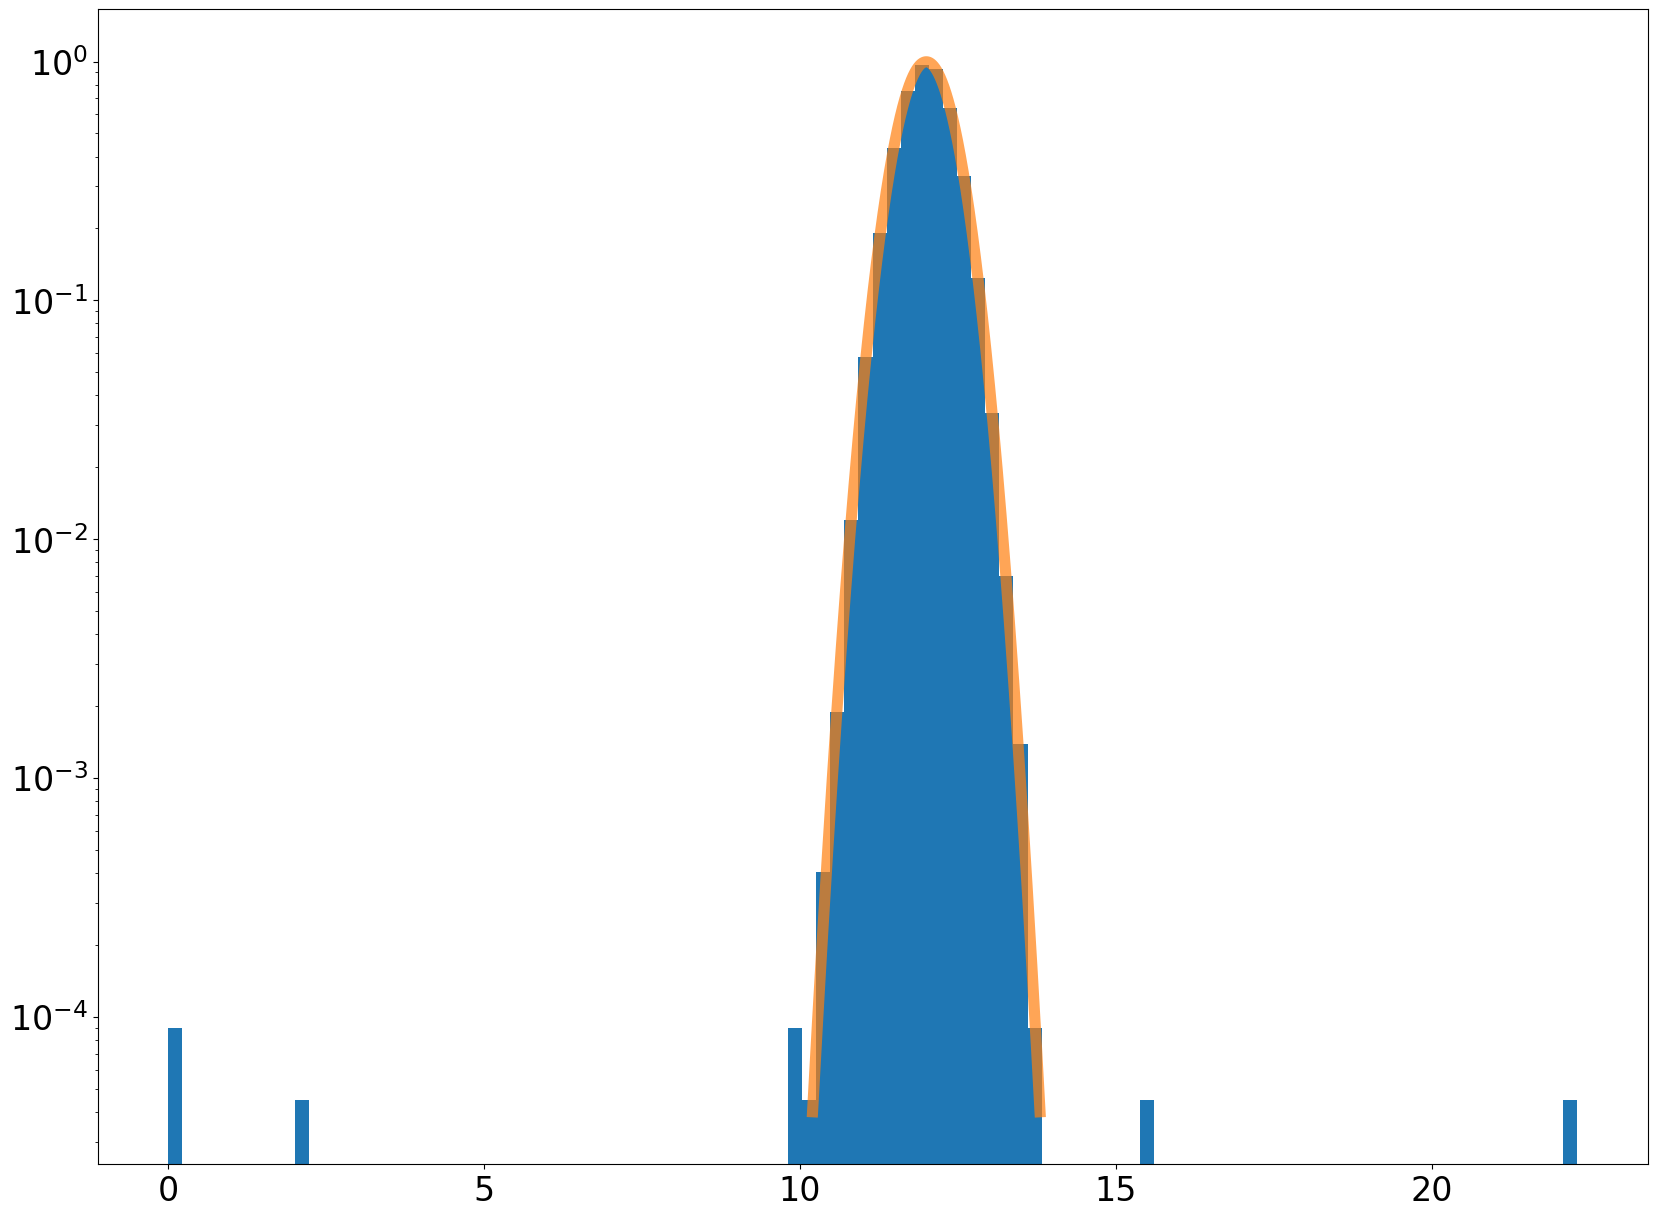

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
x = np.linspace(10.2,13.8,1000)
ax.plot(x,stats.norm.pdf(x,loc = 12., scale = 0.4),linewidth = 8,alpha = 0.7)
plt.show()

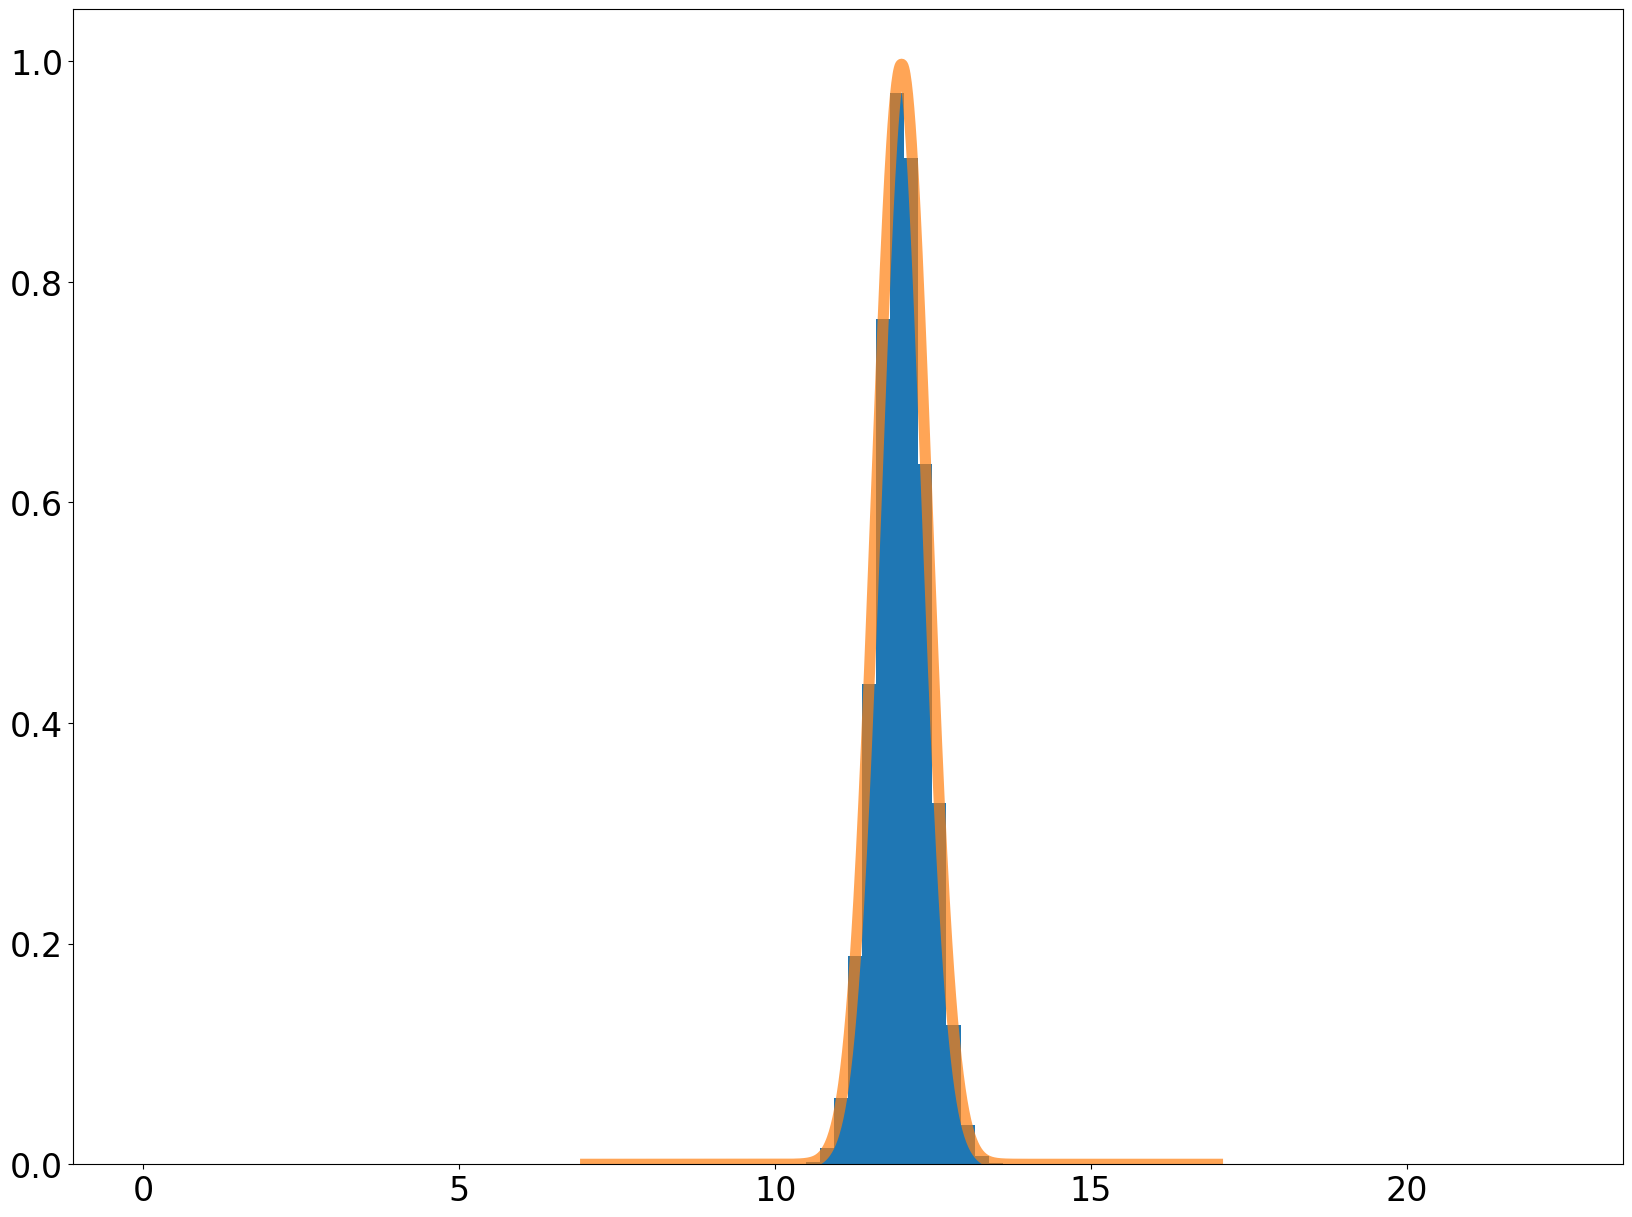

In [2]:
plt.rcParams["figure.figsize"] = (20,15)

d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d, 100, density=True)
plt.tick_params(labelsize = 24)
x = np.linspace(7,17,1000)
ax.plot(x,stats.norm.pdf(x,loc = 12., scale = 0.4),linewidth = 8,alpha = 0.7)
plt.show()

### 1A - 0

The second graph is chunky because the ax.hist is dedicating a lot of bins to nothing due to our outliers, and the outliers are invisible due to the normal y-axis, but otherwise they both look solid. The first graph definitely does a better job of showing everything, which I wouldn't usually expect from the semilog. Time to adjust my expectations.

### 1A - 1

*What is the probability that the data we threw out was due to a correct temperature reading? - i.e., what is the probability that we threw out **true** bad data? To be more precise: what is the probability that the temperature fluctuation background produced a value/signal above/below a certain threshold?*

This seems like the most prudent question given our intention here. Now we can get to the interesting stuff - we were going to throw out data from when our temperature was off anyway, but how likely is it that we threw out good data by "mistake"? I didn't phrase the original question like that so I could make the math simpler.


### 1A - 2

The probability that our temperature background produced a reading within a certain range is: $$\Huge 1 - (\int_{-\infty}^{12-p} \frac{5}{2\sqrt{2\pi}} e^{-\frac{25(x - 12)^2}{8}} + \int_{12+p}^{\infty} \frac{5}{2\sqrt{2\pi}} e^{-\frac{25(x - 12)^2}{8}})$$ where $p$ is our threshold for correct temperature readings, which I will select as $3\sigma = 1.2$.


### 1A - 3



In [3]:
bad = np.array([10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
mu, sig = 12, 0.4
p = 3 * sig
def probability(x):
    return 1 - (stats.norm.cdf(mu - x, mu, scale = sig) + stats.norm.sf(mu + x, mu, scale = sig))

print(probability(p))

0.9973002039367398


Hey, it's our 99.7. Nice to see an old friend around. So there is a 0.3% chance our background gave us a reading that is outside of this, which I can live with. I will replot with our new limits here.

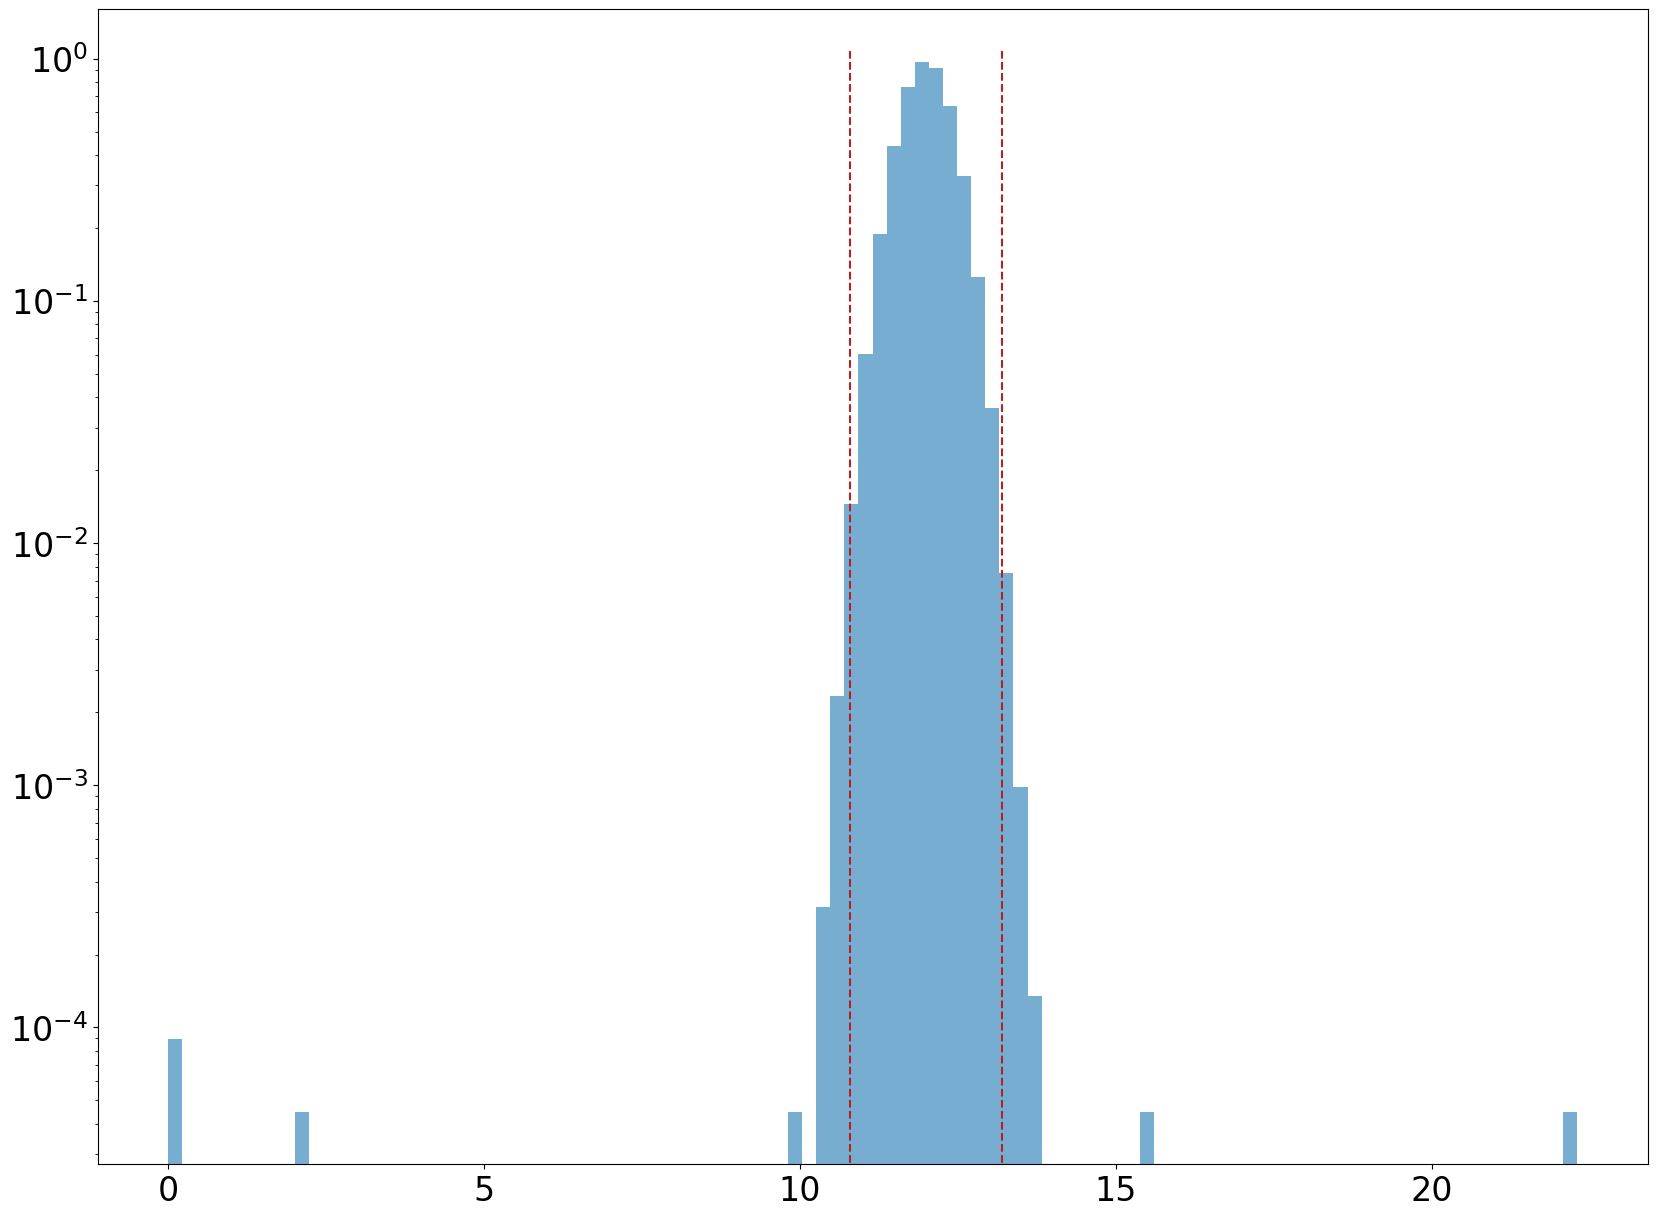

In [37]:
fig, ax = plt.subplots(1, 1)
ax.hist(d, 100, density=True, alpha = .6)
plt.tick_params(labelsize = 24)
plt.yscale('log')
ax.vlines([10.8, 13.2], 0, 1.1, linestyle = 'dashed', color = 'firebrick')
plt.show()

Hmm. Looks like we're losing a lot of data. Oops!

In [5]:
truth_1_1 = d[d < 13.2]
truth_1_1 = truth_1_1[truth_1_1 > 10.8]
print('1,1 --- ' + str(len(truth_1_1)))


1,1 --- 99738


I can use some logic to get the rest of the entries. I know that one of the bad data points, $12.7$, made it in, and I know that the other seven bad points did not. So our bottom left value is $100,000 - 99,740 = 260$.

| | **True Temp** | **Bad Temp**|
| --- | --- | --- |
| Test Good | 99,740 | 1 |
| Test Bad | 260 | 7 |

We lost 260 good data points (.026%) but kept only 1 bad data point (12.5%). We lost an insignificant amount of good data imo and avoided most of the bad, which is a solid test.

## 2



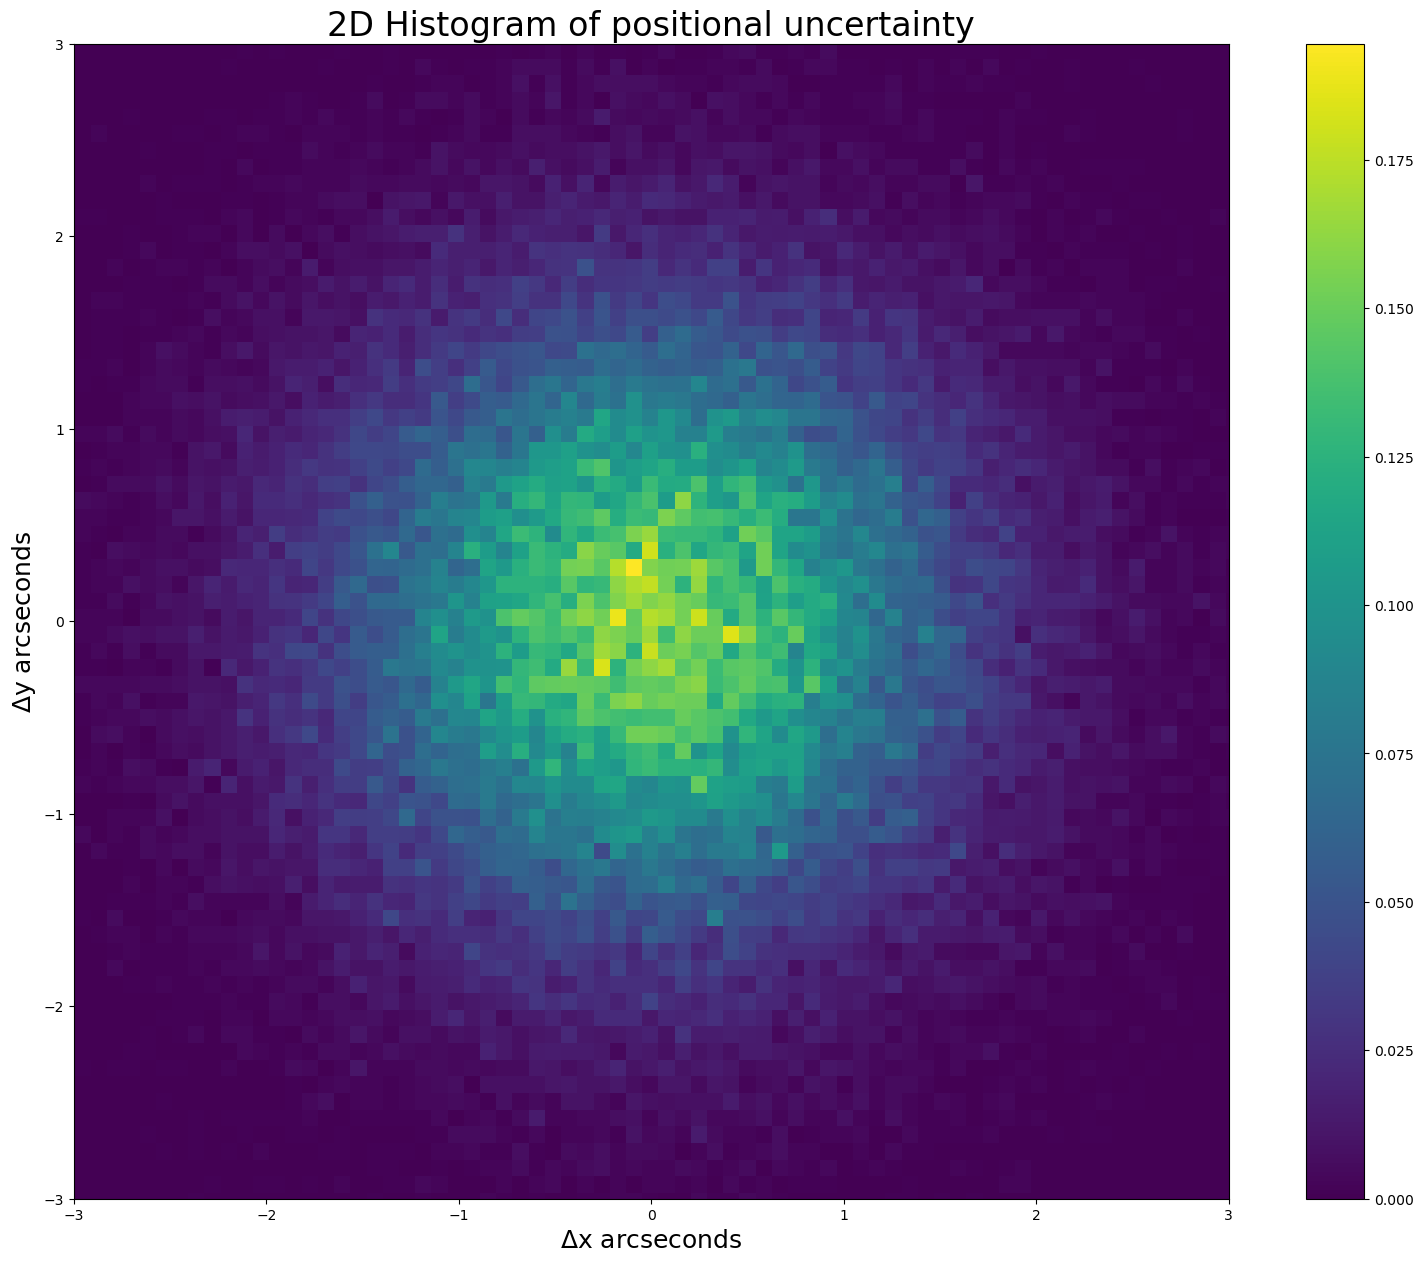

In [6]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel(r"$\Delta$y arcseconds", fontsize = 18)
plt.xlabel(r"$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

## 2A

Our question: *What is the probability that our positional uncertainty produced an apparent movement of five arcseconds or more?*

## 2B

In our homework we saw that the vector magnitude average of two Gaussians is a Rayleigh distribution, so in math:

$$\Huge P = \int_{5*\sigma}^{\infty} \frac{x}{\sigma^2} e^{\frac{-x^2}{2 \sigma^2}} dx  =  \int_{5}^{\infty} x e^{\frac{-x^2}{2}} dx$$

Let's do it in code real quick.

In [7]:
p_ast = stats.rayleigh.sf(5, scale = 1)
print(p_ast)
# now to get a sigma value
sigma = stats.norm.isf(p_ast)
print(sigma)

3.726653172078671e-06
4.480314698770361


Interesting, I would have naively expected a sigma value higher than 5 as we are squaring something.

In [8]:
fivesig = stats.norm.sf(5)
arc_needed = stats.rayleigh.isf(fivesig)
print(arc_needed)

5.489079776062419


So our necessary arcsecond value is close to 5.5: longer than just 5!

## 3A

Our question: *What is the probability that our background produced 6800 or fewer cosmic rays in a 15 day time period*? (i.e. can we really say the moon was there?)

## 3B

The math .... tricky ... let's say our *sum* is

$$\Huge \sum_{0}^{6800} \frac{6800^x e^{-6800}}{7200x!} $$

We can do this because a sum of Poissons with the certain expectations is a Poisson with expectation (sum of expectations). Very neat. Though I doubt my TI-84 would love it if I gave it this sum.

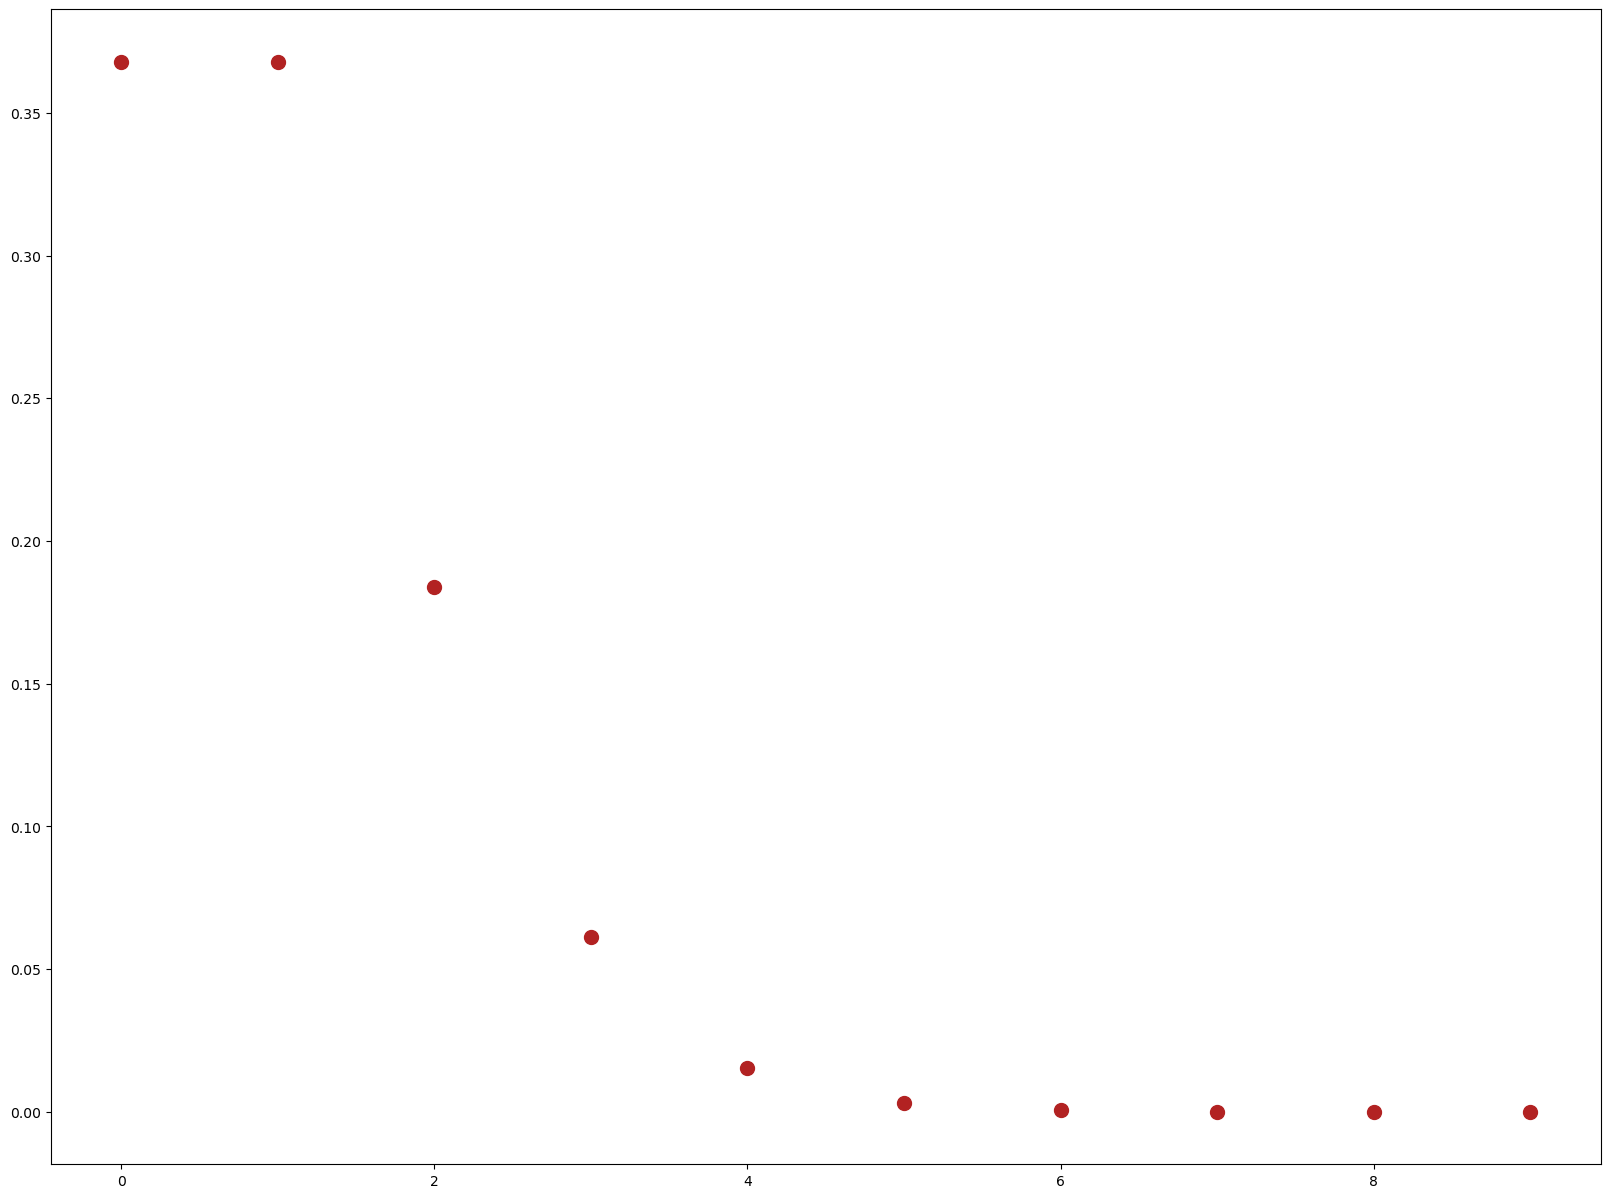

In [66]:
x = np.arange(10)
one_min = stats.poisson.pmf(x, 1)
fig, ax = plt.subplots()
ax.scatter(x, one_min, color = 'firebrick', s = 100)
plt.show()

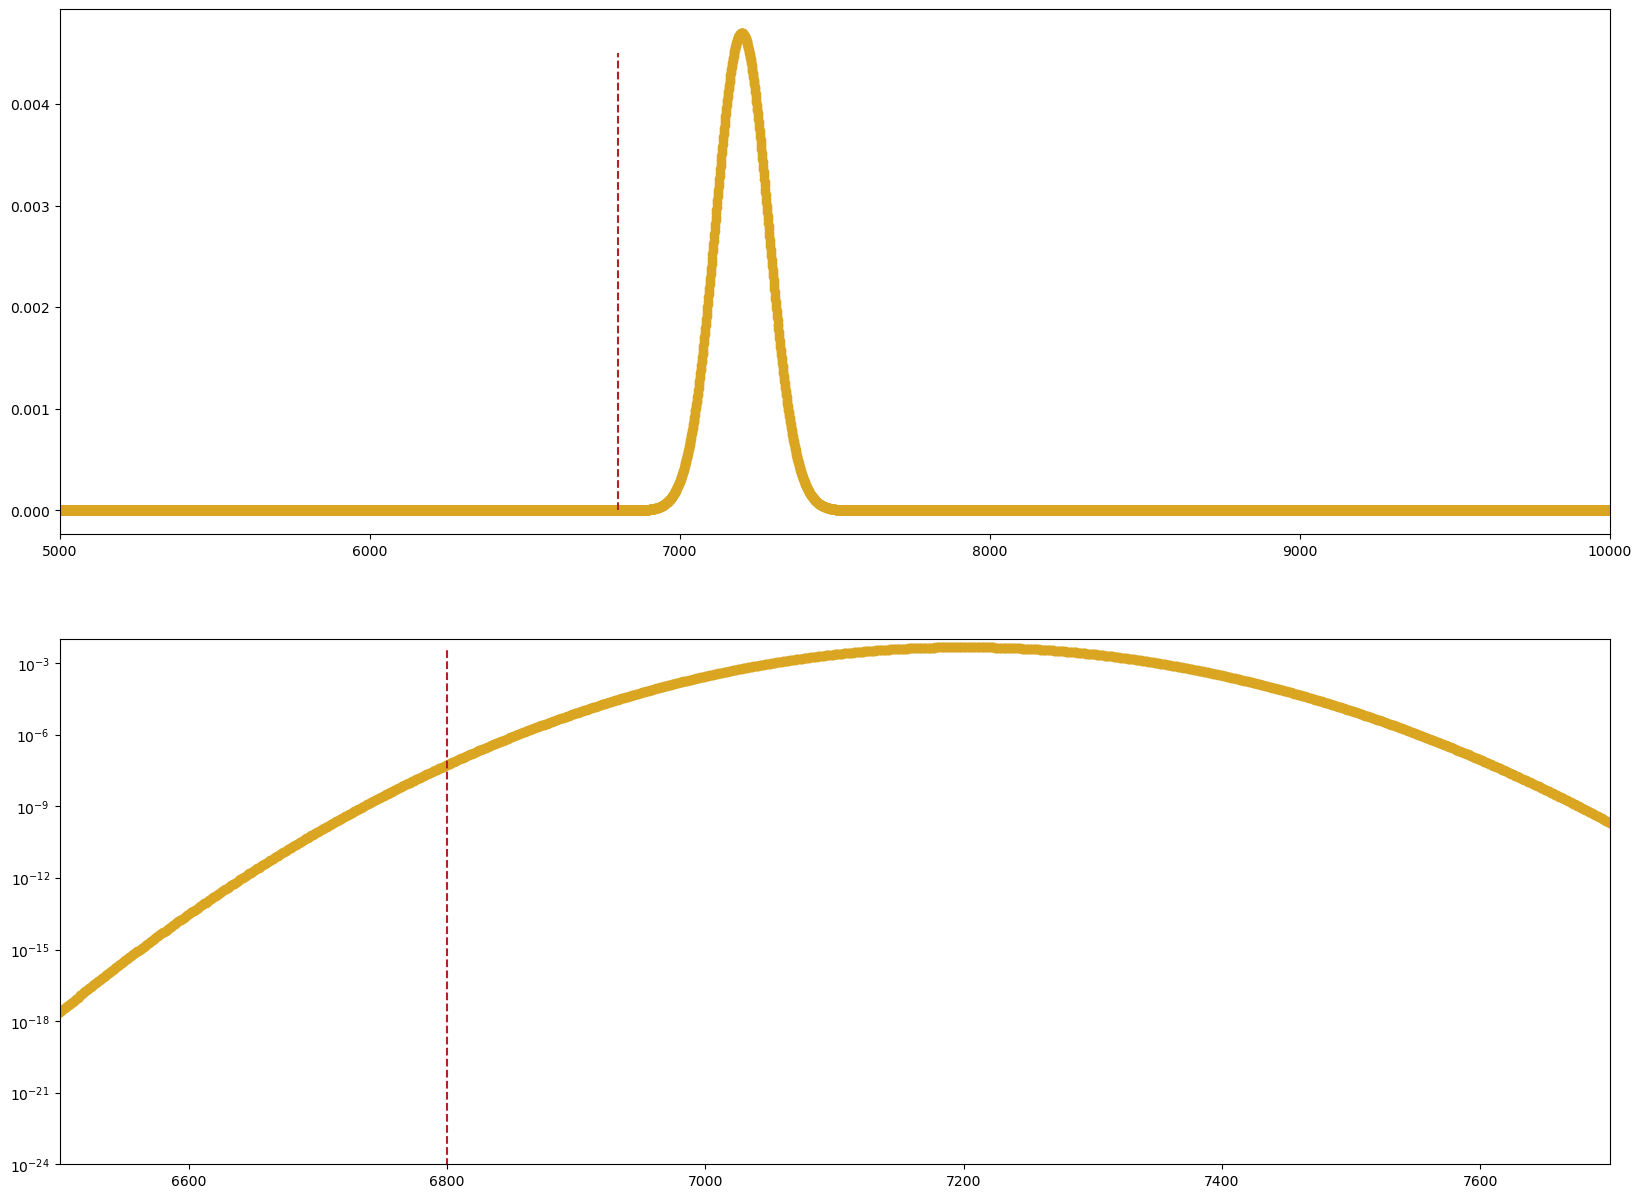

In [80]:
minutes = 8 * 15 * 60
fig, ax = plt.subplots(2)
total = one_min
for i in range(minutes):
    total = np.convolve(total, one_min, mode = 'full') # making our full convolution average over 15 nights
x_fin = x[0] * minutes + np.arange(len(total))
ax[0].scatter(x_fin, total, color = 'goldenrod', linestyle = '-')
ax[0].set_xlim(5000, 10000)
ax[1].scatter(x_fin, total, color = 'goldenrod', linestyle = '-')
ax[1].set_yscale('log')
ax[1].set_xlim(6500, 7700)
ax[1].set_ylim(10e-25, .01)
ax[0].vlines(6800, 0, .0045, linestyle = 'dashed', color = 'firebrick')
ax[1].vlines(6800, 0, .0045, linestyle = 'dashed', color = 'firebrick')
plt.show() 


Above is our cutoff at the dashed line. I think our value will be pretty small!

## 3C

In [70]:
cutoff = np.where(x_fin == 6800)[0]
cdf = np.sum(total[0:cutoff[0] + 1])
realcdf = stats.poisson.cdf(6800, 7200)
print(f"The built-in function gives {realcdf}")
print(f"My 7200 convolution monstrosity gives {cdf}")
print(f"My monstrosity sums to {np.sum(total)}") # this is close enough to 1 that i don't feel bad
moonsigma = stats.norm.ppf(cdf)
realmoonsigma = stats.norm.ppf(realcdf)
print(f"Function sigma: {moonsigma}")
print(f"Monstrosity sigma: {realmoonsigma}")

hundrethsigma = stats.norm.ppf(stats.poisson.cdf(68,72))
print(f"Our sigma if there were a hundredth of the minutes is {hundrethsigma

The built-in function gives 1.0133280183917768e-06
My 7200 convolution monstrosity gives 9.559722253100881e-07
My monstrosity sums to 0.9991979469025454
Function sigma: -4.762515565046967
Monstrosity sigma: -4.750747965777188


Huh, not quite 5 sigma. That's pretty interesting. Perhaps my visual cortex was not designed for estimating sigma values based on one single graph.

What is unique about this problem (for us at least) is the interval over which we are summing and how that requires convolutions and decreases the expected sigma due to the number of trials (7200). Receiving